<a href="https://colab.research.google.com/github/aferenaz/MLOPSII-tp5/blob/main/mini_tp5_federado_Ferenaz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini-TP 5 — Federa tu modelo y mide el trade-off (starter)

**Operaciones de Aprendizaje Automático II · CEIA – FIUBA · Entrega individual, esta semana**

Corre una **simulación federada** con FedAvg y **analiza el trade-off privacidad vs performance**. Completa las celdas marcadas con `# TODO`.

**Qué debes entregar**
1. Reparte un dataset (**el tuyo** o el provisto) entre **K clientes** y corre FedAvg.
2. Compara la accuracy **federada** contra la **centralizada**.
3. Repite con una partición **non-IID** y observa la diferencia (grafica accuracy vs ronda).
4. **Analiza el trade-off:** ¿cuánto accuracy “cuesta” no mover el dato? ¿y sumar privacidad?
5. **(Opcional)** Agrega ruido (privacidad diferencial simple) y mide el impacto.

**Se evalúa:** que corra de punta a punta; FedAvg bien implementado; comparación IID / non-IID / centralizado; y la reflexión sobre el trade-off.

> Apóyate en `federated_tutorial.ipynb`. Entorno uv: `uv add scikit-learn numpy matplotlib`.

---

**Dataset elegido:** `digits` (el provisto): 1.797 imágenes de 8×8 de dígitos, 10 clases. Mi modelo del
Mini-TP 1 (demanda de Gout) es una **regresión**, y el starter es un clasificador softmax; con
`digits`, la partición non-IID "cada cliente ve sólo algunas clases" tiene sentido directo. En la
reflexión analizo qué pasaría si federara el modelo de Gout.


In [ ]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "numpy", "matplotlib"])
print("Listo.")

Listo.


## 1. Datos y modelo

Puedes usar **tu** dataset (el de tu modelo) o el `digits` provisto para practicar la mecánica. El modelo softmax de abajo sirve como base; si usas tu modelo, adapta las funciones.

In [ ]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

rng = np.random.RandomState(0)
# TODO: reemplaza por tu dataset (X, y) si quieres federar tu propio modelo
X, y = load_digits(return_X_y=True)
X = StandardScaler().fit_transform(X)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
N_FEAT, N_CLS = X.shape[1], len(np.unique(y))

def init_modelo(): return np.zeros((N_FEAT, N_CLS)), np.zeros(N_CLS)
def softmax(Z): Z=Z-Z.max(1,keepdims=True); e=np.exp(Z); return e/e.sum(1,keepdims=True)
def onehot(y): O=np.zeros((len(y),N_CLS)); O[np.arange(len(y)),y]=1; return O
def paso_sgd(W,b,X,y,lr): P=softmax(X@W+b); D=(P-onehot(y))/len(y); return W-lr*(X.T@D), b-lr*D.sum(0)
def accuracy(W,b,X=Xte,y=yte): return (np.argmax(X@W+b,1)==y).mean()
print("Datos:", Xtr.shape, "· clases:", N_CLS)

Datos: (1347, 64) · clases: 10


## 2. Centralizado (línea de base)

In [ ]:
def entrenar_centralizado(epocas=200, lr=0.5):
    W,b=init_modelo()
    for _ in range(epocas): W,b=paso_sgd(W,b,Xtr,ytr,lr)
    return W,b
Wc,bc=entrenar_centralizado(); acc_central=accuracy(Wc,bc)
print(f"accuracy centralizada: {acc_central:.3f}")

accuracy centralizada: 0.969


## 3. FedAvg

Completa el entrenamiento local y la agregación (o reúsalos del tutorial).

In [ ]:
def entrenar_local(W_glob, b_glob, Xc, yc, epocas=25, lr=0.5):
    W,b = W_glob.copy(), b_glob.copy()          # cada cliente arranca del modelo GLOBAL de la ronda
    for _ in range(epocas):
        W,b = paso_sgd(W,b,Xc,yc,lr)            # entrena sólo con SUS datos, que nunca salen del cliente
    return W, b, len(Xc)                        # devuelve pesos y n_k, no datos

def fedavg(actualizaciones):
    # Promedio PONDERADO por nº de datos de cada cliente: w = sum_k (n_k / n) * w_k
    n = sum(nk for _,_,nk in actualizaciones)
    W = sum((nk/n)*Wk for Wk,_,nk in actualizaciones)
    b = sum((nk/n)*bk for _,bk,nk in actualizaciones)
    return W, b

def federado(clientes, R=20, frac=0.4, epocas=25, lr=0.5, sigma=0.0, seed=None):
    """FedAvg: R rondas; en cada una participa una fracción `frac` de los clientes.
    sigma > 0 agrega ruido gaussiano al modelo agregado (DP simple, sección 6)."""
    r = rng if seed is None else np.random.RandomState(seed)
    W,b=init_modelo(); K,m=len(clientes),max(1,int(frac*len(clientes))); hist=[]
    for _ in range(R):
        sel=r.choice(K,m,replace=False)
        ups=[entrenar_local(W,b,*clientes[i][:2],epocas,lr) for i in sel]
        W,b=fedavg(ups)
        if sigma > 0:
            W = W + r.normal(0, sigma, W.shape); b = b + r.normal(0, sigma, b.shape)
        hist.append(accuracy(W,b))
    return W,b,hist

# Chequeo: con dos clientes de 100 y 300 datos, el promedio pesa 1/4 y 3/4
_W, _b = fedavg([(np.ones((2,2)), np.ones(2), 100), (np.zeros((2,2)), np.zeros(2), 300)])
assert np.allclose(_W, 0.25) and np.allclose(_b, 0.25)
print("FedAvg listo (promedio ponderado verificado).")


FedAvg listo (promedio ponderado verificado).


## 4. Particiones IID y non-IID

In [ ]:
def particionar_iid(K):
    idx=rng.permutation(len(Xtr)); return [(Xtr[c],ytr[c]) for c in np.array_split(idx,K)]

def particionar_no_iid(K, clases_por_cliente=2):
    order=np.argsort(ytr); shards=np.array_split(order,K*clases_por_cliente); rng.shuffle(shards)
    out=[]
    for k in range(K):
        idx=np.concatenate(shards[k*clases_por_cliente:(k+1)*clases_por_cliente]); out.append((Xtr[idx],ytr[idx]))
    return out

# K = 5 clientes; en cada ronda participan 2 (frac = 0.4)
K = 5
part_iid, part_niid = particionar_iid(K), particionar_no_iid(K)
for nombre, part in (("IID", part_iid), ("non-IID", part_niid)):
    print(f"{nombre:<8}", " | ".join(f"c{k}: {len(yk)} datos, clases {sorted(set(yk.tolist()))}"
                                      if nombre == "non-IID" else f"c{k}: {len(yk)} datos"
                                      for k, (_, yk) in enumerate(part)))

_,_,hist_iid  = federado(part_iid, seed=1)
_,_,hist_niid = federado(part_niid, seed=1)
print(f"\ncentral={acc_central:.3f} | IID={hist_iid[-1]:.3f} | non-IID={hist_niid[-1]:.3f}")


IID      c0: 270 datos | c1: 270 datos | c2: 269 datos | c3: 269 datos | c4: 269 datos
non-IID  c0: 268 datos, clases [6, 7, 8, 9] | c1: 270 datos, clases [0, 1, 4] | c2: 270 datos, clases [3, 4, 5, 6] | c3: 270 datos, clases [1, 2, 3] | c4: 269 datos, clases [5, 9]

central=0.969 | IID=0.967 | non-IID=0.929


In [ ]:
# Comparación: la última ronda de non-IID depende de qué 2 clientes tocaron, así que también
# reporto la media y el desvío de las últimas 5 rondas, y repito con 5 semillas.
def resumen(h): return h[-1], np.mean(h[-5:]), np.std(h[-5:])

print(f"{'':<14}{'última ronda':>13}{'media últ. 5':>14}{'desvío últ. 5':>15}{'costo vs central':>18}")
print(f"{'centralizado':<14}{acc_central:>13.3f}")
for nombre, h in (("FedAvg IID", hist_iid), ("FedAvg non-IID", hist_niid)):
    u, m, s = resumen(h)
    print(f"{nombre:<14}{u:>13.3f}{m:>14.3f}{s:>15.3f}{acc_central - m:>+18.3f}")

finales = {"IID": [], "non-IID": []}
for s in range(5):
    finales["IID"].append(np.mean(federado(part_iid, seed=100 + s)[2][-5:]))
    finales["non-IID"].append(np.mean(federado(part_niid, seed=100 + s)[2][-5:]))
print("\n5 semillas (media de las últimas 5 rondas):")
for k, v in finales.items():
    print(f"  {k:<8} {np.mean(v):.3f} ± {np.std(v):.3f}  -> costo vs central {acc_central - np.mean(v):+.3f}")


               última ronda  media últ. 5  desvío últ. 5  costo vs central
centralizado          0.969
FedAvg IID            0.967         0.969          0.004            -0.000
FedAvg non-IID        0.929         0.931          0.014            +0.038

5 semillas (media de las últimas 5 rondas):
  IID      0.971 ± 0.001  -> costo vs central -0.002
  non-IID  0.942 ± 0.006  -> costo vs central +0.026


## 5. Grafica accuracy vs ronda

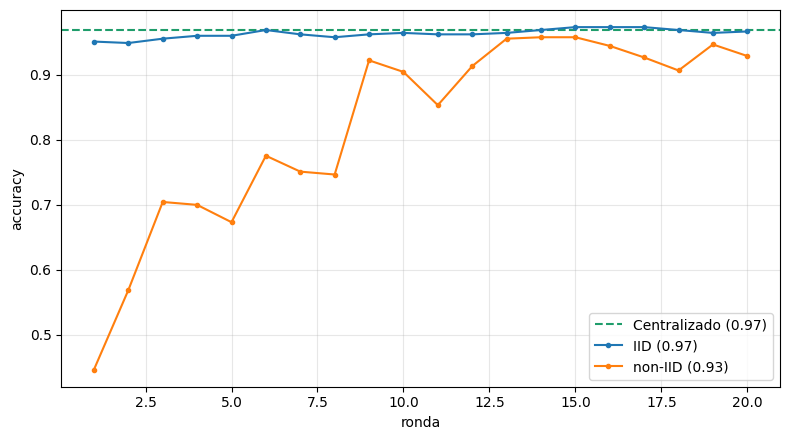

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4.5))
plt.axhline(acc_central, ls="--", color="#1F9D6B", label=f"Centralizado ({acc_central:.2f})")
plt.plot(range(1,len(hist_iid)+1),  hist_iid,  "-o", ms=3, label=f"IID ({hist_iid[-1]:.2f})")
plt.plot(range(1,len(hist_niid)+1), hist_niid, "-o", ms=3, label=f"non-IID ({hist_niid[-1]:.2f})")
plt.xlabel("ronda"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 6. (Opcional) Privacidad diferencial

Agrego ruido gaussiano $\mathcal{N}(0, \sigma^2)$ a `W` y `b` después de cada agregación (partición
IID, las mismas 5 semillas) y mido cuánto cae la accuracy. Es DP "simple": sin recorte de
gradientes ni contabilidad de ε, así que muestra el **costo en accuracy** del ruido, no una garantía
formal de privacidad.


(tamaño típico de un peso del modelo: |W| medio = 0.240)
 sigma  accuracy  ± desvío  costo vs sin ruido
   0.0     0.971     0.001              +0.000
  0.05     0.955     0.005              +0.016
   0.1     0.932     0.006              +0.039
   0.2     0.888     0.012              +0.083


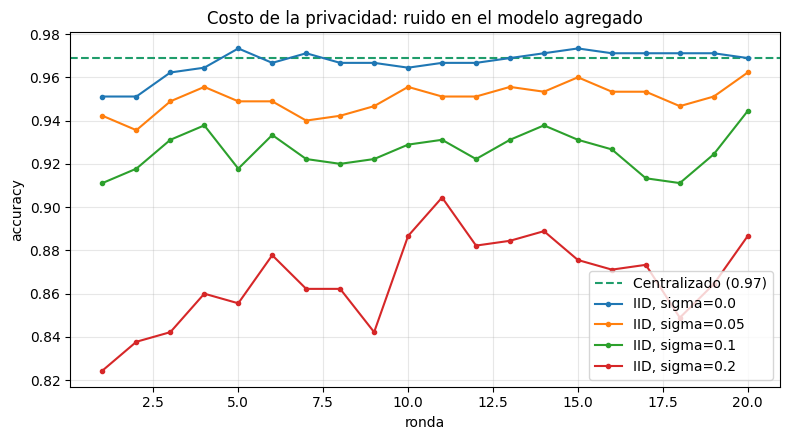

In [ ]:
SIGMAS = [0.0, 0.05, 0.1, 0.2]
dp = {s: [np.mean(federado(part_iid, sigma=s, seed=100 + k)[2][-5:]) for k in range(5)] for s in SIGMAS}
escala = np.abs(federado(part_iid, seed=100)[0]).mean()
print(f"(tamaño típico de un peso del modelo: |W| medio = {escala:.3f})")
print(f"{'sigma':>6}{'accuracy':>10}{'± desvío':>10}{'costo vs sin ruido':>20}")
for s in SIGMAS:
    print(f"{s:>6}{np.mean(dp[s]):>10.3f}{np.std(dp[s]):>10.3f}{np.mean(dp[0.0]) - np.mean(dp[s]):>+20.3f}")

plt.figure(figsize=(8, 4.5))
plt.axhline(acc_central, ls="--", color="#1F9D6B", label=f"Centralizado ({acc_central:.2f})")
for s in SIGMAS:
    plt.plot(range(1, 21), federado(part_iid, sigma=s, seed=100)[2], "-o", ms=3, label=f"IID, sigma={s}")
plt.xlabel("ronda"); plt.ylabel("accuracy"); plt.title("Costo de la privacidad: ruido en el modelo agregado")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()


### Reflexión (completa)

| | accuracy (media de las últimas 5 rondas, 5 semillas) | costo vs centralizado |
|---|---|---|
| centralizado | 0.969 | — |
| FedAvg IID | 0.971 ± 0.001 | ≈0 |
| FedAvg non-IID | 0.942 ± 0.006 | −2.6 puntos |
| FedAvg IID + ruido σ = 0.05 / 0.1 / 0.2 | 0.955 / 0.932 / 0.888 | −1.6 / −3.9 / −8.3 puntos (vs IID sin ruido) |

- **Costo de no mover el dato.** Con partición IID, federar no cuesta nada: FedAvg llega a 0.97, lo
  mismo que el centralizado. El costo aparece con datos **non-IID**: −2.6 puntos en promedio, y en la
  corrida del gráfico −3.8 puntos (0.931 contra 0.969). Además tarda mucho más en converger: arranca en
  0.44, pasa 0.90 recién en la ronda 9 y no se queda arriba de ese valor hasta la ronda 12, mientras
  que IID ya está en 0.95 en la primera ronda.
- **Estabilidad.** La curva non-IID serrucha (desvío de 0.014 en las últimas 5 rondas contra 0.004 en
  IID; caídas como 0.92 → 0.85 entre rondas). En cada ronda participan sólo 2 de los 5 clientes, y
  cada uno ve 2 a 4 dígitos: cada ronda el modelo global se tira hacia las clases de los que
  participaron y "olvida" las de los que no. Con IID, cualquier par de clientes es una muestra
  representativa, y el promedio apenas se mueve.
- **Costo de sumar privacidad.** El ruido tiene un costo claro y creciente: σ = 0.05 cuesta 1.6 puntos,
  σ = 0.1 cuesta 3.9 y σ = 0.2 cuesta 8.3 (el peso típico del modelo mide 0.24, así que σ = 0.2 es
  ruido casi del tamaño de la señal). O sea: no mover el dato sale gratis con IID, y la privacidad
  formal es lo que realmente cuesta accuracy. Esto es DP "simple", sin recorte ni contabilidad de ε.
- **En mi proyecto (Gout), el federado sería forzado.** Las 9 sucursales son de la misma empresa y las
  ventas ya se consolidan en un mismo lugar para entrenar el modelo; no hay una restricción legal ni de
  confianza que impida moverlas, así que federar sólo agregaría el costo non-IID (cada sucursal tiene
  su propio mix de productos y de demanda) sin ningún beneficio. Sería **orgánico** si el modelo se
  entrenara entre varias cadenas sin TACC que no quieren compartir sus volúmenes de venta con la
  competencia. Ahí la medida que agregaría es **agregación segura** (el servidor sólo ve la suma de
  las actualizaciones, no la de cada cadena), que no cuesta accuracy sino cómputo y comunicación; y
  ruido de DP sólo si hiciera falta una garantía formal, sabiendo que cuesta entre 1.6 y 3.9 puntos con
  σ = 0.05–0.1.
